# Classification d’images Fashion-MNIST avec un CNN

## Objectif général

Nous allons construire progressivement un **réseau de neurones convolutif**, ou **CNN** (*Convolutional Neural Network*), capable de reconnaître le type de vêtement représenté sur une image Fashion-MNIST.

Une image sera représentée par une matrice $X$ de taille $28 \times 28$. Chaque nombre de cette matrice indique l’intensité d’un pixel. La réponse attendue est une classe :

$$
y \in \{0,1,\ldots,9\}.
$$

Le travail suivra toujours le même cycle :

1. comprendre et préparer les données ;
2. construire une architecture adaptée ;
3. entraîner le modèle ;
4. évaluer ses performances ;
5. interpréter ses réussites et ses erreurs.

> Dans cette première étape, nous préparons seulement l’environnement. Aucune donnée n’est encore chargée et aucun modèle n’est encore créé.

## Protocole expérimental : éviter la fuite de données

Fashion-MNIST fournit un jeu d’apprentissage officiel et un jeu de test officiel. Plus tard, nous séparerons le jeu d’apprentissage en deux parties disjointes :

$$
D_{\text{apprentissage officiel}} = D_{\text{entraînement}} \cup D_{\text{validation}}.
$$

Le rôle de chaque partie sera différent :

- **entraînement** : calculer et modifier les paramètres du réseau ;
- **validation** : suivre l’apprentissage et choisir les réglages ;
- **test** : mesurer une seule fois la performance finale sur des exemples jamais utilisés pour décider.

Nous imposerons donc notamment :

$$
D_{\text{entraînement}} \cap D_{\text{validation}} = \varnothing
\qquad \text{et} \qquad
D_{\text{test}} \cap D_{\text{entraînement}} = \varnothing
\qquad \text{et} \qquad
D_{\text{test}} \cap D_{\text{validation}} = \varnothing.
$$

Garder le test isolé évite une **fuite de données** : si nous l’utilisions pour choisir le modèle, son score ne représenterait plus honnêtement sa capacité à généraliser.

## 1. Préparer l’environnement et la reproductibilité

L’initialisation des poids, le mélange des images et certaines opérations d’entraînement utilisent des nombres pseudo-aléatoires. Ils sont produits par un algorithme à partir d’une valeur initiale appelée **graine**, ou *seed*.

Nous choisissons ici :

$$
s = 42.
$$

Avec la même graine, le même ordre d’opérations et le même environnement logiciel, nous obtenons généralement les mêmes suites pseudo-aléatoires. Cela facilite la comparaison de deux essais. La graine ne garantit toutefois pas une identité parfaite entre des versions de bibliothèques ou des matériels différents.

`tf.keras.utils.set_random_seed(SEED)` règle ensemble les générateurs de Python, NumPy et TensorFlow. Le mode déterministe demande ensuite à TensorFlow de privilégier des opérations reproductibles ; il peut parfois ralentir les calculs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

SEED = 42

# Une seule graine pour Python, NumPy et TensorFlow.
tf.keras.utils.set_random_seed(SEED)

# Demande des opérations déterministes lorsque TensorFlow les prend en charge.
tf.config.experimental.enable_op_determinism()

print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("Graine     :", SEED)
print("Environnement prêt.")

TensorFlow : 2.21.0
NumPy      : 2.4.6
Graine     : 42
Environnement prêt.


### Bilan de l’étape

À ce stade :

- les bibliothèques nécessaires au démarrage sont importées ;
- les expériences futures seront plus faciles à reproduire ;
- aucune image n’a encore été chargée ou transformée ;
- le jeu de test n’a pas été consulté.

**Étape suivante :** comprendre comment une image en niveaux de gris devient une matrice de nombres, puis charger Fashion-MNIST.

## 2. Comprendre et charger Fashion-MNIST

### 2.1 Une image en niveaux de gris est une matrice

Une image Fashion-MNIST mesure 28 pixels de hauteur et 28 pixels de largeur. Elle contient donc :

$$
28 \times 28 = 784 \text{ pixels}.
$$

Comme l’image est en niveaux de gris, chaque pixel est représenté par un seul entier. Pour le pixel placé à la ligne $r$ et à la colonne $c$ :

$$
p_{r,c} \in \{0,1,\ldots,255\},
\qquad r,c \in \{0,1,\ldots,27\}.
$$

La valeur 0 représente le noir, 255 le blanc, et les valeurs intermédiaires des nuances de gris. Une image brute $X_i$ est donc une matrice :

$$
X_i \in \{0,\ldots,255\}^{28 \times 28}.
$$

En Python, `images[i, r, c]` désigne le pixel de coordonnées $(r,c)$ dans l’image numéro $i$. Une image est un tableau de rang 2. Un ensemble de $N$ images est un tenseur de rang 3 :

$$
\mathcal{X} \in \{0,\ldots,255\}^{N \times 28 \times 28}.
$$

À chaque image $X_i$ correspond une étiquette entière $y_i$ :

$$
y_i \in \{0,1,\ldots,9\}.
$$

Ces nombres sont seulement des identifiants de catégories : la classe 9 n’est pas « plus grande » que la classe 2.

### 2.2 Charger les données sans les transformer

Keras fournit Fashion-MNIST sous la forme de deux couples :

$$
(X_{\text{train}}, y_{\text{train}})
\qquad \text{et} \qquad
(X_{\text{test}}, y_{\text{test}}).
$$

Nous appelons le premier tableau `images_train_complet_brutes` :

- **train complet** : la partie validation n’a pas encore été extraite ;
- **brutes** : les valeurs sont encore des entiers entre 0 et 255.

Le jeu de test doit être chargé pour être conservé, mais il ne servira ni à choisir l’architecture, ni à régler le modèle, ni à décider quand arrêter l’entraînement. À cette étape, nous ne normalisons rien et nous ne construisons aucun réseau.

In [2]:
(
    (images_train_complet_brutes, etiquettes_train_complet),
    (images_test_brutes, etiquettes_test),
) = tf.keras.datasets.fashion_mnist.load_data()

print("Fashion-MNIST est chargé.")

Fashion-MNIST est chargé.


### 2.3 Vérifier les dimensions et les types

Les dimensions attendues sont :

$$
X_{\text{train}} \in \{0,\ldots,255\}^{60000 \times 28 \times 28},
\qquad
y_{\text{train}} \in \{0,\ldots,9\}^{60000},
$$

$$
X_{\text{test}} \in \{0,\ldots,255\}^{10000 \times 28 \times 28},
\qquad
y_{\text{test}} \in \{0,\ldots,9\}^{10000}.
$$

La première dimension de $X$ doit être égale à la longueur de $y$ : chaque image possède exactement une étiquette.

Les pixels sont stockés avec le type `uint8`, c’est-à-dire un entier non signé sur 8 bits. Huit bits permettent de coder :

$$
2^8 = 256
$$

valeurs différentes, de 0 à 255. Les étiquettes restent des entiers ; nous ne les transformons pas en vecteurs *one-hot*.

In [3]:
print("Images train complètes :", images_train_complet_brutes.shape)
print("Étiquettes train       :", etiquettes_train_complet.shape)
print("Images test            :", images_test_brutes.shape)
print("Étiquettes test        :", etiquettes_test.shape)
print()
print("Type des images       :", images_train_complet_brutes.dtype)
print("Type des étiquettes   :", etiquettes_train_complet.dtype)
print("Pixels du train       :", images_train_complet_brutes.min(), "à", images_train_complet_brutes.max())
print("Classes du train      :", np.unique(etiquettes_train_complet))

assert images_train_complet_brutes.shape == (60_000, 28, 28)
assert etiquettes_train_complet.shape == (60_000,)
assert images_test_brutes.shape == (10_000, 28, 28)
assert etiquettes_test.shape == (10_000,)
assert images_train_complet_brutes.dtype == np.uint8
assert images_test_brutes.dtype == np.uint8
assert np.issubdtype(etiquettes_train_complet.dtype, np.integer)
assert np.issubdtype(etiquettes_test.dtype, np.integer)
assert len(images_train_complet_brutes) == len(etiquettes_train_complet)
assert len(images_test_brutes) == len(etiquettes_test)
assert images_train_complet_brutes.min() == 0
assert images_train_complet_brutes.max() == 255
assert images_test_brutes.min() == 0
assert images_test_brutes.max() == 255
assert np.array_equal(np.unique(etiquettes_train_complet), np.arange(10))
assert np.array_equal(np.unique(etiquettes_test), np.arange(10))

print("\nToutes les vérifications sont réussies.")

Images train complètes : (60000, 28, 28)
Étiquettes train       : (60000,)
Images test            : (10000, 28, 28)
Étiquettes test        : (10000,)

Type des images       : uint8
Type des étiquettes   : uint8
Pixels du train       : 0 à 255
Classes du train      : [0 1 2 3 4 5 6 7 8 9]

Toutes les vérifications sont réussies.


### Bilan de l’étape 2

Nous disposons maintenant de 60 000 images d’apprentissage et de 10 000 images de test. Chaque image brute est une matrice $28 \times 28$ de type `uint8`, et chaque étiquette est un entier compris entre 0 et 9.

Le jeu de test a seulement fait l’objet de contrôles structurels. Il n’a servi à aucune décision. Nous n’avons encore effectué ni normalisation, ni séparation de validation, ni visualisation, ni construction du CNN.

**Étape suivante :** traduire les identifiants 0 à 9 en noms de vêtements et explorer visuellement quelques images du jeu d’apprentissage.

## 3. Associer les classes à des vêtements

### 3.1 Décoder une étiquette

L’étiquette $y_i$ d’une image est un entier entre 0 et 9. Pour la convertir en texte, nous utilisons une table de correspondance $C$ :

$$
\operatorname{nom}(y_i) = C[y_i].
$$

Par exemple, $C[0]$ désigne un T-shirt ou un haut, tandis que $C[9]$ désigne une bottine. Le numéro n’est pas une mesure : il sert uniquement d’adresse dans la table.

| Identifiant | Nom officiel | Traduction française |
|---:|---|---|
| 0 | T-shirt/top | T-shirt / haut |
| 1 | Trouser | Pantalon |
| 2 | Pullover | Pull |
| 3 | Dress | Robe |
| 4 | Coat | Manteau |
| 5 | Sandal | Sandale |
| 6 | Shirt | Chemise |
| 7 | Sneaker | Basket |
| 8 | Bag | Sac |
| 9 | Ankle boot | Bottine |

In [4]:
noms_classes_officiels = np.array(
    [
        "T-shirt/top",
        "Trouser",
        "Pullover",
        "Dress",
        "Coat",
        "Sandal",
        "Shirt",
        "Sneaker",
        "Bag",
        "Ankle boot",
    ]
)

noms_classes_fr = np.array(
    [
        "T-shirt / haut",
        "Pantalon",
        "Pull",
        "Robe",
        "Manteau",
        "Sandale",
        "Chemise",
        "Basket",
        "Sac",
        "Bottine",
    ]
)

assert len(noms_classes_officiels) == 10
assert len(noms_classes_fr) == 10

for identifiant, (nom_officiel, nom_fr) in enumerate(
    zip(noms_classes_officiels, noms_classes_fr)
):
    print(f"{identifiant} : {nom_fr} ({nom_officiel})")

0 : T-shirt / haut (T-shirt/top)
1 : Pantalon (Trouser)
2 : Pull (Pullover)
3 : Robe (Dress)
4 : Manteau (Coat)
5 : Sandale (Sandal)
6 : Chemise (Shirt)
7 : Basket (Sneaker)
8 : Sac (Bag)
9 : Bottine (Ankle boot)


### 3.2 Choisir et afficher une image par classe

Pour chaque classe $k$, nous cherchons uniquement dans le jeu d’apprentissage les indices tels que $y_i=k$. Nous retenons le premier :

$$
i_k = \min \left\{i \in \{0,\ldots,59999\} \mid y_i=k\right\},
\qquad k \in \{0,\ldots,9\}.
$$

L’image affichée pour la classe $k$ sera donc $X_{i_k}$. Cette règle est déterministe : tant que l’ordre du jeu d’apprentissage ne change pas, nous retrouvons les mêmes dix images.

`imshow` convertit visuellement la valeur brute $p$ en une intensité comprise entre 0 et 1 :

$$
g(p)=\frac{p}{255}.
$$

Cette conversion sert seulement à l’affichage : elle ne modifie pas les tableaux. `vmin=0` et `vmax=255` imposent la même échelle de gris aux dix images, et `interpolation="nearest"` laisse visibles les pixels d’origine. Aucune image de test ne sera consultée.

Indices sélectionnés : [1, 16, 5, 3, 19, 8, 18, 6, 23, 0]


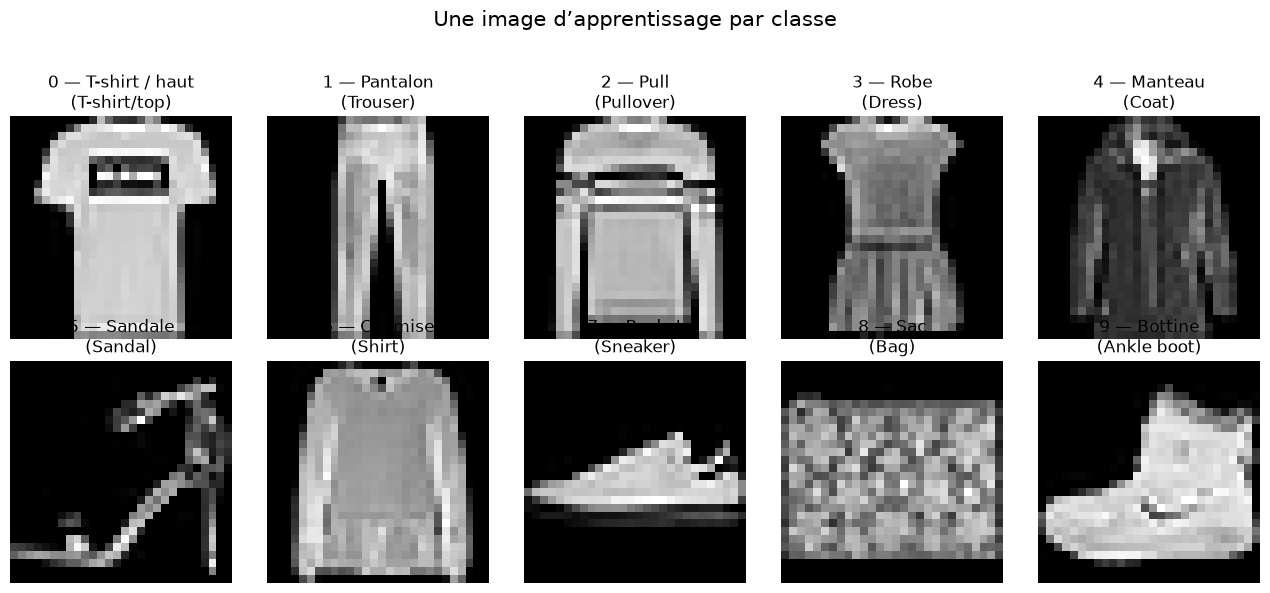

In [5]:
premiers_indices = []

for identifiant in range(10):
    candidats = np.flatnonzero(etiquettes_train_complet == identifiant)
    assert candidats.size > 0
    premiers_indices.append(int(candidats[0]))

assert len(set(premiers_indices)) == 10
assert all(
    etiquettes_train_complet[indice] == identifiant
    for identifiant, indice in enumerate(premiers_indices)
)

print("Indices sélectionnés :", premiers_indices)

figure, axes = plt.subplots(2, 5, figsize=(13, 6))

for identifiant, (axe, indice) in enumerate(
    zip(axes.ravel(), premiers_indices)
):
    axe.imshow(
        images_train_complet_brutes[indice],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    axe.set_title(
        f"{identifiant} — {noms_classes_fr[identifiant]}\n"
        f"({noms_classes_officiels[identifiant]})"
    )
    axe.axis("off")

figure.suptitle("Une image d’apprentissage par classe", fontsize=15)
figure.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

### Lecture prudente et bilan de l’étape 3

Les images paraissent pixelisées parce qu’elles ne contiennent que $28 \times 28$ pixels. Certaines silhouettes sont visuellement très différentes, comme un sac et une bottine. D’autres catégories de hauts peuvent se ressembler. Il s’agit seulement d’observations descriptives, pas encore d’erreurs du modèle : aucun modèle n’a été entraîné.

Une seule image par classe ne représente pas toute la diversité des vêtements. Cette grille ne permet donc aucune conclusion sur l’accuracy, la généralisation ou la difficulté réelle de chaque classe.

Nous avons exclusivement affiché des images d’apprentissage. Les tableaux sont toujours bruts et le jeu de test reste réservé à l’évaluation finale.

**Étape suivante :** étudier la répartition des classes, puis séparer correctement l’apprentissage et la validation.

## 4. Analyser les classes et créer la validation

### 4.1 Mesurer la répartition des classes

Avant de séparer les données, nous vérifions si certaines classes sont plus représentées que d’autres. Pour une classe $k$, son effectif est :

$$
n_k = \sum_{i=0}^{N-1} \mathbf{1}(y_i=k).
$$

La fonction indicatrice $\mathbf{1}(y_i=k)$ vaut 1 si l’image $i$ appartient à la classe $k$, et 0 sinon. Sa proportion est :

$$
p_k = \frac{n_k}{N}.
$$

Ici, $N=60000$. Un jeu est équilibré lorsque les proportions des classes sont proches. Avec dix classes parfaitement équilibrées, nous obtenons :

$$
p_k = \frac{1}{10} = 0.10 = 10\%.
$$

`np.bincount` compte combien de fois chaque étiquette entière apparaît. Nous l’appliquons uniquement aux étiquettes du train officiel.

0 — T-shirt / haut    :  6000 (10.0%)
1 — Pantalon          :  6000 (10.0%)
2 — Pull              :  6000 (10.0%)
3 — Robe              :  6000 (10.0%)
4 — Manteau           :  6000 (10.0%)
5 — Sandale           :  6000 (10.0%)
6 — Chemise           :  6000 (10.0%)
7 — Basket            :  6000 (10.0%)
8 — Sac               :  6000 (10.0%)
9 — Bottine           :  6000 (10.0%)


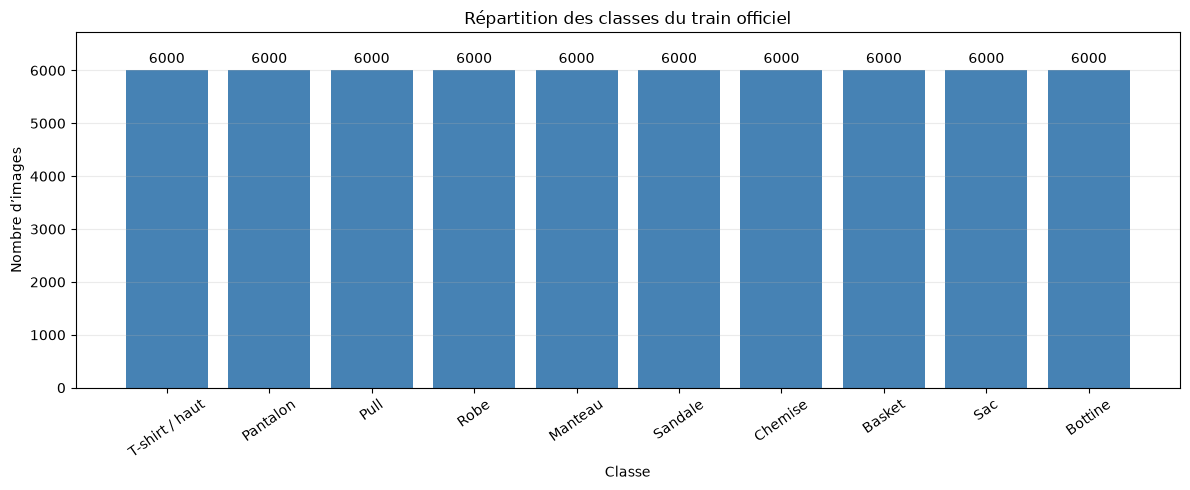

In [6]:
effectifs_train_officiel = np.bincount(
    etiquettes_train_complet,
    minlength=len(noms_classes_fr),
)
proportions_train_officiel = (
    effectifs_train_officiel / len(etiquettes_train_complet)
)

for identifiant in range(len(noms_classes_fr)):
    print(
        f"{identifiant} — {noms_classes_fr[identifiant]:<17} : "
        f"{effectifs_train_officiel[identifiant]:5d} "
        f"({proportions_train_officiel[identifiant]:.1%})"
    )

assert np.array_equal(effectifs_train_officiel, np.full(10, 6_000))

figure, axe = plt.subplots(figsize=(12, 5))
barres = axe.bar(
    noms_classes_fr,
    effectifs_train_officiel,
    color="steelblue",
)
axe.set_title("Répartition des classes du train officiel")
axe.set_xlabel("Classe")
axe.set_ylabel("Nombre d’images")
axe.tick_params(axis="x", rotation=35)
axe.bar_label(barres, padding=3)
axe.set_ylim(0, effectifs_train_officiel.max() * 1.12)
axe.grid(axis="y", alpha=0.25)
figure.tight_layout()
plt.show()

### 4.2 Séparer le train officiel en entraînement et validation

Le futur modèle apprendra ses paramètres sur 80 % des 60 000 images. Les 20 % restantes permettront de suivre sa généralisation pendant le développement :

$$
N_{\text{train}} = 0.80 \times 60000 = 48000,
$$

$$
N_{\text{validation}} = 0.20 \times 60000 = 12000.
$$

Nous séparons d’abord l’ensemble des indices :

$$
I = \{0,1,\ldots,N-1\}.
$$

Cette méthode conserve l’identité des observations et permettra de vérifier formellement qu’aucun indice n’est partagé.

L’option `stratify=etiquettes_train_complet` demande de préserver la proportion de chaque classe. En général :

$$
p_{\text{train},k} \approx p_{\text{validation},k} \approx p_k.
$$

L’option `random_state=SEED` rend le tirage reproductible et `shuffle=True` mélange les indices avant leur répartition. Le test officiel n’intervient jamais dans ce calcul.

In [7]:
from sklearn.model_selection import train_test_split

indices_officiels = np.arange(len(images_train_complet_brutes))

indices_train, indices_validation = train_test_split(
    indices_officiels,
    test_size=0.20,
    random_state=SEED,
    shuffle=True,
    stratify=etiquettes_train_complet,
)

images_train_brutes = images_train_complet_brutes[indices_train]
etiquettes_train = etiquettes_train_complet[indices_train]
images_validation_brutes = images_train_complet_brutes[indices_validation]
etiquettes_validation = etiquettes_train_complet[indices_validation]

print("Images d’entraînement :", images_train_brutes.shape)
print("Images de validation   :", images_validation_brutes.shape)

Images d’entraînement : (48000, 28, 28)
Images de validation   : (12000, 28, 28)


### 4.3 Vérifier la partition et la stratification

Une séparation correcte doit respecter quatre propriétés.

**1. Les tailles attendues**

$$
|I_{\text{train}}|=48000
\qquad \text{et} \qquad
|I_{\text{validation}}|=12000.
$$

**2. La disjonction : aucune image ne doit appartenir aux deux ensembles**

$$
I_{\text{train}} \cap I_{\text{validation}} = \varnothing.
$$

**3. L’exhaustivité : toutes les images du train officiel doivent être conservées**

$$
I_{\text{train}} \cup I_{\text{validation}} = I.
$$

**4. La conservation des proportions**

$$
p_{\text{train},k}=\frac{n_{\text{train},k}}{N_{\text{train}}}
\qquad \text{et} \qquad
p_{\text{validation},k}=\frac{n_{\text{validation},k}}{N_{\text{validation}}}.
$$

Comme les effectifs sont parfaitement divisibles ici, chaque classe doit contenir exactement 4 800 images d’entraînement et 1 200 images de validation, soit 10 % dans les deux cas.

In [8]:
intersection = np.intersect1d(indices_train, indices_validation)
indices_reconstitues = np.sort(
    np.concatenate([indices_train, indices_validation])
)

effectifs_train = np.bincount(etiquettes_train, minlength=10)
effectifs_validation = np.bincount(etiquettes_validation, minlength=10)
proportions_train = effectifs_train / len(etiquettes_train)
proportions_validation = (
    effectifs_validation / len(etiquettes_validation)
)

print(
    f"{'Classe':<18}"
    f"{'Train':>9}"
    f"{'Validation':>12}"
    f"{'% train':>11}"
    f"{'% val.':>10}"
)
for identifiant in range(10):
    print(
        f"{noms_classes_fr[identifiant]:<18}"
        f"{effectifs_train[identifiant]:>9}"
        f"{effectifs_validation[identifiant]:>12}"
        f"{proportions_train[identifiant]:>10.1%}"
        f"{proportions_validation[identifiant]:>10.1%}"
    )

assert images_train_brutes.shape == (48_000, 28, 28)
assert images_validation_brutes.shape == (12_000, 28, 28)
assert etiquettes_train.shape == (48_000,)
assert etiquettes_validation.shape == (12_000,)
assert images_train_brutes.dtype == np.uint8
assert images_validation_brutes.dtype == np.uint8
assert len(np.unique(indices_train)) == len(indices_train)
assert len(np.unique(indices_validation)) == len(indices_validation)
assert intersection.size == 0
assert np.array_equal(indices_reconstitues, indices_officiels)
assert np.array_equal(effectifs_train, np.full(10, 4_800))
assert np.array_equal(effectifs_validation, np.full(10, 1_200))
assert np.allclose(proportions_train, proportions_validation)

print("\nIntersection :", intersection.size, "indice")
print("Union reconstituée :", len(indices_reconstitues), "indices")
print("La partition est disjointe, exhaustive et stratifiée.")

Classe                Train  Validation    % train    % val.
T-shirt / haut         4800        1200     10.0%     10.0%
Pantalon               4800        1200     10.0%     10.0%
Pull                   4800        1200     10.0%     10.0%
Robe                   4800        1200     10.0%     10.0%
Manteau                4800        1200     10.0%     10.0%
Sandale                4800        1200     10.0%     10.0%
Chemise                4800        1200     10.0%     10.0%
Basket                 4800        1200     10.0%     10.0%
Sac                    4800        1200     10.0%     10.0%
Bottine                4800        1200     10.0%     10.0%

Intersection : 0 indice
Union reconstituée : 60000 indices
La partition est disjointe, exhaustive et stratifiée.


### Bilan de l’étape 4

Le train officiel est parfaitement équilibré : chaque classe contient 6 000 images, soit 10 %. Nous l’avons séparé en 48 000 images d’entraînement et 12 000 images de validation.

La partition est reproductible, stratifiée, disjointe et exhaustive. Chaque sous-ensemble conserve 10 % de chaque classe. Le jeu officiel de test est toujours séparé et n’a participé à aucune décision.

Toutes les images sont encore des matrices brutes `uint8` comprises entre 0 et 255. Aucun modèle n’a été construit.

**Étape suivante :** normaliser les pixels et ajouter la dimension de canal attendue par un CNN.

## 5. Préparer les images pour le CNN

### 5.1 Normaliser les intensités des pixels

Les pixels bruts sont des entiers compris entre 0 et 255 :

$$
p \in \{0,1,\ldots,255\}.
$$

Nous les convertissons en nombres décimaux compris entre 0 et 1 avec la transformation :

$$
T(p)=p_{\text{normalisé}}=\frac{\operatorname{float32}(p)}{255}.
$$

Ainsi, $T(0)=0$ et $T(255)=1$. Les distances relatives entre les intensités sont conservées, mais leur échelle numérique devient plus petite, ce qui facilite généralement l’optimisation par descente de gradient.

Le type `float32` est celui couramment utilisé par TensorFlow : il permet les calculs décimaux tout en consommant deux fois moins de mémoire que `float64`. Nous effectuons la conversion avant la division.

La division par 255 est une règle fixe connue à l’avance : elle ne calcule ni moyenne, ni écart-type, ni autre paramètre à partir des données. La même formule peut donc être appliquée au train, à la validation et au test sans fuite de données. Une standardisation fondée sur une moyenne et un écart-type serait différente : ces statistiques devraient être apprises uniquement sur le train.

Nous créons de nouveaux tableaux et conservons les tableaux `*_brutes` intacts. Chaque réexécution repart ainsi des valeurs originales et ne peut pas normaliser deux fois les mêmes pixels.

In [9]:
ECHELLE_PIXEL = np.float32(255.0)

images_train_normalisees = (
    images_train_brutes.astype(np.float32) / ECHELLE_PIXEL
)
images_validation_normalisees = (
    images_validation_brutes.astype(np.float32) / ECHELLE_PIXEL
)
images_test_normalisees = (
    images_test_brutes.astype(np.float32) / ECHELLE_PIXEL
)

ensembles_normalises = [
    ("Entraînement", images_train_brutes, images_train_normalisees),
    ("Validation", images_validation_brutes, images_validation_normalisees),
    ("Test", images_test_brutes, images_test_normalisees),
]

for nom, images_brutes, images_normalisees in ensembles_normalises:
    print(
        f"{nom:<14} : forme={images_normalisees.shape}, "
        f"type={images_normalisees.dtype}, "
        f"plage=[{images_normalisees.min():.1f}, "
        f"{images_normalisees.max():.1f}]"
    )
    assert images_brutes.dtype == np.uint8
    assert images_normalisees.dtype == np.float32
    assert images_normalisees.shape == images_brutes.shape
    assert images_normalisees.min() == 0.0
    assert images_normalisees.max() == 1.0
    assert not np.shares_memory(images_brutes, images_normalisees)

ligne, colonne = 14, 14
pixel_brut = images_train_brutes[0, ligne, colonne]
pixel_normalise = images_train_normalisees[0, ligne, colonne]
assert np.isclose(pixel_normalise, np.float32(pixel_brut) / ECHELLE_PIXEL)
print(
    f"\nExemple — pixel ({ligne}, {colonne}) : "
    f"{pixel_brut} devient {pixel_normalise:.6f}"
)

Entraînement   : forme=(48000, 28, 28), type=float32, plage=[0.0, 1.0]
Validation     : forme=(12000, 28, 28), type=float32, plage=[0.0, 1.0]
Test           : forme=(10000, 28, 28), type=float32, plage=[0.0, 1.0]

Exemple — pixel (14, 14) : 181 devient 0.709804


### 5.2 Ajouter la dimension du canal

Nos lots sont actuellement des tenseurs de rang 3 :

$$
X \in \mathbb{R}^{N \times 28 \times 28}.
$$

Une couche `Conv2D` de Keras utilise par défaut le format `channels_last`, dont l’ordre des axes est :

$$
(N,H,W,C),
$$

où $N$ est le nombre d’images, $H$ la hauteur, $W$ la largeur et $C$ le nombre de canaux. Une image couleur possède généralement trois canaux rouge, vert et bleu. Fashion-MNIST est en niveaux de gris, donc :

$$
C=1.
$$

Nous ajoutons un dernier axe de longueur 1 :

$$
(N,28,28) \longrightarrow (N,28,28,1).
$$

Mathématiquement, le contenu reste identique :

$$
X^{\text{CNN}}_{i,h,w,0}=X^{\text{normalisé}}_{i,h,w}.
$$

L’ajout du canal ne crée donc aucun pixel. Pour une image seule, le futur réseau recevra `input_shape=(28, 28, 1)` ; la dimension variable du lot $N$ n’est pas incluse dans `input_shape`.

In [10]:
assert tf.keras.backend.image_data_format() == "channels_last"

images_train = np.expand_dims(images_train_normalisees, axis=-1)
images_validation = np.expand_dims(
    images_validation_normalisees, axis=-1
)
images_test = np.expand_dims(images_test_normalisees, axis=-1)

FORME_ENTREE_CNN = images_train.shape[1:]

tenseurs_cnn = [
    ("Entraînement", images_train, images_train_normalisees, (48_000, 28, 28, 1)),
    ("Validation", images_validation, images_validation_normalisees, (12_000, 28, 28, 1)),
    ("Test", images_test, images_test_normalisees, (10_000, 28, 28, 1)),
]

for nom, images_cnn, images_normalisees, forme_attendue in tenseurs_cnn:
    print(
        f"{nom:<14} : forme={images_cnn.shape}, "
        f"type={images_cnn.dtype}, "
        f"plage=[{images_cnn.min():.1f}, {images_cnn.max():.1f}]"
    )
    assert images_cnn.shape == forme_attendue
    assert images_cnn.dtype == np.float32
    assert images_cnn.min() == 0.0
    assert images_cnn.max() == 1.0
    assert np.array_equal(images_cnn[..., 0], images_normalisees)

assert FORME_ENTREE_CNN == (28, 28, 1)
print("\nForme d’une entrée du CNN :", FORME_ENTREE_CNN)

Entraînement   : forme=(48000, 28, 28, 1), type=float32, plage=[0.0, 1.0]


Validation     : forme=(12000, 28, 28, 1), type=float32, plage=[0.0, 1.0]
Test           : forme=(10000, 28, 28, 1), type=float32, plage=[0.0, 1.0]

Forme d’une entrée du CNN : (28, 28, 1)


### Bilan de l’étape 5

Pour chaque ensemble, nous avons appliqué la transformation fixe :

$$
p_{\text{normalisé}}=\frac{p_{\text{brut}}}{255}.
$$

Les tenseurs `images_train`, `images_validation` et `images_test` sont désormais de type `float32`, compris entre 0 et 1, et possèdent un canal explicite. Leurs formes sont respectivement `(48000, 28, 28, 1)`, `(12000, 28, 28, 1)` et `(10000, 28, 28, 1)`.

Les données brutes ont été conservées. La transformation du test est strictement identique et n’a appris aucun paramètre ; le test n’a servi à aucune décision. Aucun modèle n’a encore été construit.

**Étape suivante :** comprendre les opérations d’un CNN, puis construire son architecture couche par couche.

## 6. Comprendre et construire le CNN

### 6.1 La convolution 2D

Une image d’entrée est un tenseur $X \in \mathbb{R}^{H \times W \times C_{\text{in}}}$. Une couche convolutive fait glisser plusieurs petits filtres sur cette image. Pour le filtre $f$, Keras calcule en pratique une corrélation croisée :

$$
Z_{i,j,f}=b_f+
\sum_{u=0}^{K_h-1}
\sum_{v=0}^{K_w-1}
\sum_{c=0}^{C_{\text{in}}-1}
W_{u,v,c,f}\,\widetilde{X}_{i+u,j+v,c}.
$$

Dans cette formule, $W_{u,v,c,f}$ est un poids appris, $b_f$ le biais du filtre et $\widetilde{X}$ l’image complétée par du *padding*. Keras appelle cette opération une convolution même si, au sens mathématique strict, le noyau n’est pas retourné.

Le même filtre est utilisé à toutes les positions : c’est le **partage des poids**. Un filtre peut ainsi détecter un motif local, comme un bord, où qu’il apparaisse dans l’image.

Pour un filtre carré de taille $K$, un pas $S$ et un padding $P$, la dimension spatiale de sortie est :

$$
H_{\text{sortie}}=
\left\lfloor\frac{H_{\text{entrée}}+2P-K}{S}\right\rfloor+1.
$$

Avec un noyau $3 \times 3$, `padding="same"` ajoute ici une bordure $P=1$ et le pas vaut $S=1$. La hauteur et la largeur sont donc conservées.

Le nombre de paramètres entraînables d’une convolution est :

$$
(K_h K_w C_{\text{in}}+1)C_{\text{out}},
$$

où le terme $+1$ représente un biais par filtre, et non un biais par pixel.

### 6.2 ReLU et max-pooling

Après chaque convolution, nous appliquons la fonction d’activation ReLU :

$$
\operatorname{ReLU}(z)=\max(0,z).
$$

Elle conserve une réponse positive et remplace une réponse négative par zéro. Sa dérivée, utilisée par la descente de gradient, vaut :

$$
\operatorname{ReLU}'(z)=
\begin{cases}
0 & \text{si } z<0,\\
1 & \text{si } z>0.
\end{cases}
$$

Au point $z=0$, la dérivée mathématique n’est pas définie ; les bibliothèques utilisent une convention numérique. ReLU introduit la non-linéarité qui permet au réseau d’apprendre des relations complexes. Elle ne possède aucun paramètre.

Le max-pooling conserve ensuite la valeur maximale de chaque fenêtre $2 \times 2$. Avec un pas de 2 :

$$
Y_{i,j,c}=\max_{0\leq u<2,\,0\leq v<2}
X_{2i+u,2j+v,c}.
$$

Il divise la hauteur et la largeur par deux :

$$
28 \times 28 \longrightarrow 14 \times 14
\longrightarrow 7 \times 7.
$$

Le pooling réduit le coût de calcul et rend les représentations moins sensibles aux petits déplacements. Il ne possède aucun paramètre entraînable, mais il perd volontairement une partie de la précision spatiale.

### 6.3 Passer des caractéristiques aux probabilités

Après les deux blocs convolutifs, le tenseur a la forme $7 \times 7 \times 64$. `Flatten` le transforme, sans modifier ses valeurs, en un vecteur de longueur :

$$
7 \times 7 \times 64=3136.
$$

Une couche dense calcule :

$$
z=xW+b.
$$

Avec $n_{\text{in}}$ entrées et $n_{\text{out}}$ neurones, elle contient :

$$
(n_{\text{in}}+1)n_{\text{out}}
$$

paramètres, le $+1$ correspondant aux biais.

Le Dropout de taux $r=0.30$ désactive aléatoirement 30 % des activations pendant l’entraînement. Sa probabilité de conservation vaut $q=1-r=0.70$. Le Dropout inversé calcule alors :

$$
\widetilde{h}_j=\frac{m_j}{q}h_j,
\qquad m_j \sim \operatorname{Bernoulli}(q).
$$

Pendant la validation et la prédiction, le Dropout est désactivé. Il aide à limiter le surapprentissage et ne contient aucun paramètre.

La dernière couche dense produit dix **logits** $z_0,\ldots,z_9$. Softmax les transforme en probabilités. Pour éviter des exponentielles inutilement grandes, on peut soustraire $m=\max_j z_j$ sans changer le résultat :

$$
\widehat{p}_k=
\frac{e^{z_k-m}}{\sum_{j=0}^{9}e^{z_j-m}},
\qquad \sum_{k=0}^{9}\widehat{p}_k=1.
$$

La classe prédite sera $\widehat{y}=\operatorname*{argmax}_k \widehat{p}_k$.

### 6.4 Architecture retenue

Le premier bloc apprend 32 motifs simples. Après réduction spatiale, le second bloc combine ces motifs avec 64 filtres. Les activations ReLU sont placées dans des couches séparées afin que chaque opération apparaisse clairement dans le résumé.

| Couche | Forme de sortie, hors lot | Paramètres |
|---|---:|---:|
| Entrée | $28 \times 28 \times 1$ | 0 |
| Conv2D, 32 filtres $3 \times 3$ | $28 \times 28 \times 32$ | 320 |
| ReLU | $28 \times 28 \times 32$ | 0 |
| MaxPool $2 \times 2$ | $14 \times 14 \times 32$ | 0 |
| Conv2D, 64 filtres $3 \times 3$ | $14 \times 14 \times 64$ | 18 496 |
| ReLU | $14 \times 14 \times 64$ | 0 |
| MaxPool $2 \times 2$ | $7 \times 7 \times 64$ | 0 |
| Flatten | 3 136 | 0 |
| Dense | 128 | 401 536 |
| ReLU puis Dropout | 128 | 0 |
| Dense, logits | 10 | 1 290 |
| Softmax | 10 | 0 |

Les calculs des paramètres sont :

$$
(3\times3\times1+1)\times32=320,
$$

$$
(3\times3\times32+1)\times64=18496,
$$

$$
(3136+1)\times128=401536,
$$

$$
(128+1)\times10=1290.
$$

Le total attendu vaut :

$$
320+18496+401536+1290=421642.
$$

La majorité des paramètres se trouve dans la couche dense de 128 neurones, ce qui crée un risque de surapprentissage ; le Dropout aidera à le limiter. À cette étape, le modèle est construit mais pas compilé ni entraîné.

In [11]:
modele_cnn = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=FORME_ENTREE_CNN, name="entree"),
        tf.keras.layers.Conv2D(
            filters=32,
            kernel_size=(3, 3),
            strides=(1, 1),
            padding="same",
            activation=None,
            name="conv_1",
        ),
        tf.keras.layers.ReLU(name="relu_1"),
        tf.keras.layers.MaxPooling2D(
            pool_size=(2, 2),
            strides=(2, 2),
            name="pool_1",
        ),
        tf.keras.layers.Conv2D(
            filters=64,
            kernel_size=(3, 3),
            strides=(1, 1),
            padding="same",
            activation=None,
            name="conv_2",
        ),
        tf.keras.layers.ReLU(name="relu_2"),
        tf.keras.layers.MaxPooling2D(
            pool_size=(2, 2),
            strides=(2, 2),
            name="pool_2",
        ),
        tf.keras.layers.Flatten(name="flatten"),
        tf.keras.layers.Dense(
            units=128, activation=None, name="dense_128"
        ),
        tf.keras.layers.ReLU(name="relu_dense"),
        tf.keras.layers.Dropout(rate=0.30, name="dropout"),
        tf.keras.layers.Dense(
            units=10, activation=None, name="logits"
        ),
        tf.keras.layers.Softmax(name="probabilites"),
    ],
    name="cnn_fashion_mnist",
)

modele_cnn.summary()

Model: "cnn_fashion_mnist"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (ReLU)                   │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (ReLU)                   │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_dense (ReLU)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilites (Softmax)          │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

### 6.5 Vérifier le modèle sans l’entraîner

Dans le résumé Keras, `None` représente la taille variable du lot. Par exemple, `(None, 28, 28, 32)` signifie que chaque image du lot produit 32 cartes de caractéristiques de taille $28 \times 28$.

Nous allons comparer les nombres de paramètres calculés à ceux des couches Keras, puis créer deux images artificielles entièrement nulles :

$$
X_{\text{fictif}} \in \mathbb{R}^{2 \times 28 \times 28 \times 1}.
$$

Le modèle doit produire :

$$
\widehat{P}_{\text{fictif}} \in \mathbb{R}^{2 \times 10},
\qquad \sum_{k=0}^{9}\widehat{p}_{i,k}=1.
$$

`training=False` désactive le Dropout. Ce passage vérifie seulement la compatibilité des dimensions et Softmax ; il ne mesure aucune performance, car les poids viennent juste d’être initialisés. Le lot fictif ne provient ni du train, ni de la validation, ni du test.

In [12]:
parametres_attendus = {
    "conv_1": 320,
    "conv_2": 18_496,
    "dense_128": 401_536,
    "logits": 1_290,
}

for nom_couche, nombre_attendu in parametres_attendus.items():
    nombre_obtenu = modele_cnn.get_layer(nom_couche).count_params()
    print(f"{nom_couche:<10} : {nombre_obtenu:>7} paramètres")
    assert nombre_obtenu == nombre_attendu

NOMBRE_PARAMETRES_CNN = sum(parametres_attendus.values())
assert NOMBRE_PARAMETRES_CNN == 421_642
assert modele_cnn.count_params() == NOMBRE_PARAMETRES_CNN
assert modele_cnn.input_shape == (None, 28, 28, 1)
assert modele_cnn.output_shape == (None, 10)

lot_fictif = tf.zeros((2, *FORME_ENTREE_CNN), dtype=tf.float32)
probabilites_fictives = modele_cnn(lot_fictif, training=False).numpy()
sommes_probabilites = probabilites_fictives.sum(axis=1)

print("\nTotal :", modele_cnn.count_params(), "paramètres")
print("Forme du lot fictif :", lot_fictif.shape)
print("Forme de la sortie  :", probabilites_fictives.shape)
print("Première sortie     :", np.round(probabilites_fictives[0], 4))
print("Sommes des lignes   :", sommes_probabilites)

assert probabilites_fictives.shape == (2, 10)
assert np.all(np.isfinite(probabilites_fictives))
assert np.all((probabilites_fictives >= 0) & (probabilites_fictives <= 1))
np.testing.assert_allclose(sommes_probabilites, np.ones(2), atol=1e-6)

print("\nArchitecture et propagation fictive validées.")

conv_1     :     320 paramètres
conv_2     :   18496 paramètres
dense_128  :  401536 paramètres
logits     :    1290 paramètres



Total : 421642 paramètres
Forme du lot fictif : (2, 28, 28, 1)
Forme de la sortie  : (2, 10)
Première sortie     : [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
Sommes des lignes   : [1. 1.]

Architecture et propagation fictive validées.


### Bilan de l’étape 6

Le CNN contient deux blocs `Conv2D → ReLU → MaxPooling2D` pour extraire progressivement des caractéristiques visuelles, puis un classifieur `Flatten → Dense → ReLU → Dropout → Dense → Softmax`.

Il attend une entrée de forme `(28, 28, 1)`, produit dix probabilités et contient exactement 421 642 paramètres entraînables. Une propagation sur un lot artificiel confirme que chaque ligne de sortie somme à 1.

Le modèle n’a été ni compilé ni entraîné. Aucune image d’entraînement, de validation ou de test n’a été utilisée pour cette vérification structurelle.

**Étape suivante :** comprendre la fonction de perte, l’accuracy et l’optimiseur Adam, puis compiler le CNN.

## 7. Choisir la perte, la métrique et l’optimiseur

### 7.1 Entropie croisée catégorielle sparse

Pour chaque image $i$, le CNN produit dix probabilités $\widehat{p}_{i,k}$ telles que :

$$
0 \leq \widehat{p}_{i,k} \leq 1,
\qquad \sum_{k=0}^{9}\widehat{p}_{i,k}=1.
$$

L’étiquette réelle reste un entier $y_i \in \{0,\ldots,9\}$. La perte d’une image est l’opposé du logarithme de la probabilité attribuée à sa vraie classe :

$$
\ell_i=-\log\left(\widehat{p}_{i,y_i}\right).
$$

Pour un lot de $B$ images, la réduction par défaut calcule la moyenne :

$$
L_B=-\frac{1}{B}\sum_{i=1}^{B}
\log\left(\widehat{p}_{i,y_i}\right).
$$

Une prédiction correcte et confiante donne une petite perte : $-\log(0.9)\approx0.105$. Attribuer seulement 0.1 à la vraie classe donne $-\log(0.1)\approx2.303$.

Nous choisissons `SparseCategoricalCrossentropy` parce que les étiquettes sont des entiers, et non des vecteurs *one-hot*. Comme le modèle possède déjà une couche Softmax, ses sorties sont des probabilités : `from_logits=False`. Mettre `from_logits=True` ou ajouter une deuxième Softmax serait incohérent.

### 7.2 Accuracy multiclasse

La classe prédite est :

$$
\widehat{y}_i=\operatorname*{argmax}_k \widehat{p}_{i,k}.
$$

L’accuracy mesure la proportion de prédictions correctes :

$$
\operatorname{Accuracy}=\frac{1}{B}
\sum_{i=1}^{B}\mathbf{1}(\widehat{y}_i=y_i).
$$

Elle est facile à interpréter, mais l’opération `argmax` est discontinue et ne fournit pas un gradient utile. Adam minimisera donc la perte différentiable ; l’accuracy servira uniquement au suivi. Deux modèles peuvent avoir la même accuracy mais des pertes différentes, car la perte tient compte de leur confiance.

In [13]:
fonction_perte = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=False,
    name="entropie_croisee_sparse",
)
metrique_accuracy = tf.keras.metrics.SparseCategoricalAccuracy(
    name="accuracy"
)

etiquettes_synthetiques = tf.constant([2, 1], dtype=tf.int32)
probabilites_synthetiques = np.zeros((2, 10), dtype=np.float32)

# Exemple 1 : vraie classe 2, prédiction correcte avec probabilité 0.70.
probabilites_synthetiques[0] = 0.30 / 9
probabilites_synthetiques[0, 2] = 0.70

# Exemple 2 : vraie classe 1, mais la classe 0 obtient la probabilité maximale.
probabilites_synthetiques[1, 2:] = 0.20 / 8
probabilites_synthetiques[1, 0] = 0.60
probabilites_synthetiques[1, 1] = 0.20
probabilites_synthetiques = tf.constant(probabilites_synthetiques)

perte_synthetique = fonction_perte(
    etiquettes_synthetiques, probabilites_synthetiques
).numpy()
accuracies_synthetiques = tf.keras.metrics.sparse_categorical_accuracy(
    etiquettes_synthetiques, probabilites_synthetiques
).numpy()
accuracy_synthetique = accuracies_synthetiques.mean()
perte_calculee_a_la_main = (-np.log(0.70) - np.log(0.20)) / 2

print("Perte Keras         :", f"{perte_synthetique:.6f}")
print("Perte calculée main :", f"{perte_calculee_a_la_main:.6f}")
print("Prédictions justes :", accuracies_synthetiques.astype(int))
print("Accuracy            :", f"{accuracy_synthetique:.1%}")

np.testing.assert_allclose(
    probabilites_synthetiques.numpy().sum(axis=1), np.ones(2), atol=1e-6
)
np.testing.assert_allclose(
    perte_synthetique, perte_calculee_a_la_main, rtol=1e-6
)
np.testing.assert_allclose(accuracy_synthetique, 0.5)

Perte Keras         :

 0.983056
Perte calculée main : 0.983056
Prédictions justes : [1 0]
Accuracy            : 50.0%


### 7.3 Optimiseur Adam

La rétropropagation calcule, à l’itération $t$, le gradient de la perte par rapport à chaque paramètre $\theta$ :

$$
g_t=\nabla_{\theta}L_B(\theta_{t-1}).
$$

Adam entretient une moyenne mobile des gradients, appelée premier moment :

$$
m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,
$$

et une moyenne mobile de leurs carrés, appelée second moment :

$$
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.
$$

Avec $m_0=v_0=0$, l’implémentation locale de Keras corrige le biais des premiers instants grâce au taux effectif :

$$
\alpha_t=\eta\frac{\sqrt{1-\beta_2^t}}{1-\beta_1^t}.
$$

Chaque paramètre est ensuite mis à jour, élément par élément, selon :

$$
\theta_t=\theta_{t-1}-
\alpha_t\frac{m_t}{\sqrt{v_t}+\varepsilon}.
$$

Nous utiliserons $\eta=10^{-3}$, $\beta_1=0.9$, $\beta_2=0.999$ et $\varepsilon=10^{-7}$. Le premier moment stabilise la direction récente du gradient ; le second adapte la taille du pas à chaque paramètre ; $\varepsilon$ évite une division par zéro. Aucun de ces calculs ne sera effectué avant l’appel futur à `fit`.

In [14]:
TAUX_APPRENTISSAGE = 1e-3
BETA_1 = 0.9
BETA_2 = 0.999
EPSILON_ADAM = 1e-7

optimiseur_adam = tf.keras.optimizers.Adam(
    learning_rate=TAUX_APPRENTISSAGE,
    beta_1=BETA_1,
    beta_2=BETA_2,
    epsilon=EPSILON_ADAM,
    amsgrad=False,
)
configuration_adam = optimiseur_adam.get_config()

print("Taux d’apprentissage :", configuration_adam["learning_rate"])
print("Bêta 1               :", configuration_adam["beta_1"])
print("Bêta 2               :", configuration_adam["beta_2"])
print("Epsilon              :", configuration_adam["epsilon"])
print("AMSGrad              :", configuration_adam["amsgrad"])

assert np.isclose(configuration_adam["learning_rate"], 1e-3)
assert configuration_adam["beta_1"] == 0.9
assert configuration_adam["beta_2"] == 0.999
assert configuration_adam["epsilon"] == 1e-7
assert configuration_adam["amsgrad"] is False
assert int(optimiseur_adam.iterations.numpy()) == 0

Taux d’apprentissage : 0.0010000000474974513
Bêta 1               : 0.9
Bêta 2               : 0.999
Epsilon              : 1e-07
AMSGrad              : False


### 7.4 Compiler le CNN

La compilation associe au modèle trois éléments :

- la perte à minimiser : entropie croisée catégorielle sparse ;
- la règle de mise à jour : Adam ;
- la métrique à afficher : accuracy sparse.

La configuration est cohérente :

$$
\text{Softmax explicite}
\quad\Longleftrightarrow\quad
\texttt{from\_logits=False}.
$$

`compile` prépare les calculs qui seront utilisés plus tard. Il ne lit aucune image, ne réalise aucune propagation, ne calcule aucun gradient et ne modifie aucun poids. Nous allons le vérifier en copiant les poids avant la compilation et en les comparant ensuite.

In [15]:
poids_avant_compilation = [
    variable.numpy().copy() for variable in modele_cnn.weights
]

modele_cnn.compile(
    optimizer=optimiseur_adam,
    loss=fonction_perte,
    metrics=[metrique_accuracy],
)

for poids_avant, variable_apres in zip(
    poids_avant_compilation, modele_cnn.weights
):
    np.testing.assert_array_equal(poids_avant, variable_apres.numpy())

assert modele_cnn.compiled
assert fonction_perte.from_logits is False
assert int(optimiseur_adam.iterations.numpy()) == 0
assert modele_cnn.count_params() == 421_642

print("Optimiseur :", type(modele_cnn.optimizer).__name__)
print("Perte      :", modele_cnn.loss.name)
print("from_logits:", modele_cnn.loss.from_logits)
print("Itérations :", int(modele_cnn.optimizer.iterations.numpy()))
print("Paramètres :", modele_cnn.count_params())
print("\nLe modèle est compilé et aucun poids n’a été modifié.")

Optimiseur : Adam
Perte      : entropie_croisee_sparse
from_logits: False
Itérations : 0
Paramètres : 421642

Le modèle est compilé et aucun poids n’a été modifié.


### Bilan de l’étape 7

Le CNN est maintenant configuré pour minimiser :

$$
L_B=-\frac{1}{B}\sum_{i=1}^{B}
\log\left(\widehat{p}_{i,y_i}\right).
$$

Adam transformera les futurs gradients de cette perte en mises à jour des 421 642 paramètres. L’accuracy mesurera la proportion de classes correctement prédites, mais ne sera pas directement optimisée.

La compilation n’a utilisé aucune image réelle, n’a effectué aucune itération d’Adam et n’a modifié aucun poids. Le modèle n’a toujours pas été entraîné.

> **Avertissement Windows :** TensorFlow peut indiquer que le GPU n’est pas disponible sous Windows natif pour cette version. Ce message est informatif, pas une erreur : le notebook fonctionne avec le processeur, mais l’entraînement sera plus lent qu’avec un GPU compatible.

**Étape suivante :** entraîner avec validation et arrêt anticipé, puis interpréter les courbes de perte et d’accuracy.

## 8. Entraîner avec validation et arrêt anticipé

### 8.1 Mini-lots, mises à jour et époques

L’ensemble d’entraînement contient $N_{\text{train}}=48000$ images. Nous choisissons des mini-lots de $B=128$ images. Le nombre de mini-lots par époque est donc :

$$
\frac{48000}{128}=375.
$$

Pour chaque mini-lot, le réseau réalise successivement :

1. une propagation avant et le calcul des probabilités ;
2. le calcul de la perte moyenne $L_B$ ;
3. la rétropropagation du gradient $\nabla_{\theta}L_B$ ;
4. une mise à jour des paramètres $\theta$ par Adam.

Une époque correspond à un passage complet sur les 48 000 images : elle contient donc 375 mises à jour. Avec `shuffle=True`, Keras mélange uniquement les exemples d’entraînement avant chaque époque afin que les mini-lots ne conservent pas toujours la même composition.

Après chaque époque, le réseau est évalué sur les 12 000 images de validation. Durant cette phase, aucun gradient n’est calculé, aucun poids n’est modifié et le Dropout est désactivé. La validation estime la généralisation sur des images qui n’ont pas servi aux mises à jour.

La perte d’entraînement est mesurée pendant que les poids évoluent et que le Dropout est actif, tandis que la perte de validation est calculée après l’époque avec des poids fixes et sans Dropout. Une perte d’entraînement parfois supérieure à la perte de validation n’est donc pas automatiquement anormale. Le test officiel reste totalement inutilisé.

### 8.2 Arrêt anticipé

Nous autorisons au maximum 20 époques, mais ce maximum n’est pas un objectif à atteindre. Le callback surveille la perte de validation $L_{\text{val}}$. Une époque $t$ est considérée comme suffisamment meilleure si :

$$
L_{\text{val},t}<L_{\text{val},\text{meilleure}}-10^{-3}.
$$

Les réglages choisis sont :

- `monitor="val_loss"` : suivre la perte de validation ;
- `mode="min"` : une valeur plus petite est meilleure ;
- `min_delta=0.001` : ignorer les variations inférieures à $10^{-3}$ ;
- `patience=3` : tolérer trois époques consécutives sans amélioration suffisante ;
- `restore_best_weights=True` : restaurer les meilleurs poids mémorisés.

Si l’arrêt se produit à l’époque $t$, les poids finaux ne sont donc pas forcément ceux de $t$ : le callback revient à la meilleure époque qu’il a reconnue. La validation sert ici à choisir l’époque d’arrêt ; c’est précisément pour cela que le test doit rester séparé jusqu’à l’évaluation finale.

In [16]:
TAILLE_LOT = 128
EPOQUES_MAX = 20
PATIENCE = 3
AMELIORATION_MINIMALE = 1e-3
LOTS_PAR_EPOQUE = int(np.ceil(len(images_train) / TAILLE_LOT))

arret_anticipe = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    min_delta=AMELIORATION_MINIMALE,
    patience=PATIENCE,
    restore_best_weights=True,
    verbose=1,
)

print("Images d’entraînement :", len(images_train))
print("Taille d’un mini-lot  :", TAILLE_LOT)
print("Mini-lots par époque  :", LOTS_PAR_EPOQUE)
print("Époques maximales     :", EPOQUES_MAX)
print("Patience              :", PATIENCE)

assert len(images_train) == 48_000
assert len(images_validation) == 12_000
assert LOTS_PAR_EPOQUE == 375

Images d’entraînement : 48000
Taille d’un mini-lot  : 128
Mini-lots par époque  : 375
Époques maximales     : 20
Patience              : 3


### 8.3 Lancer l’entraînement

La méthode `fit` réalise automatiquement les propagations avant, les calculs de perte, les rétropropagations et les mises à jour Adam. Elle enregistre après chaque époque :

- `loss` et `accuracy` pour l’entraînement ;
- `val_loss` et `val_accuracy` pour la validation.

Ces séries seront disponibles dans `historique_cnn.history`. Le paramètre `verbose=2` produit une ligne de résultats par époque sans barre de progression volumineuse.

> **Attention à la réexécution :** relancer uniquement la cellule suivante continuerait l’apprentissage à partir des poids actuels. Pour refaire une expérience indépendante, il faut réexécuter le notebook depuis la cellule d’initialisation afin de reconstruire et recompiler un modèle neuf avec la même graine.

In [17]:
historique_cnn = modele_cnn.fit(
    images_train,
    etiquettes_train,
    validation_data=(images_validation, etiquettes_validation),
    epochs=EPOQUES_MAX,
    batch_size=TAILLE_LOT,
    shuffle=True,
    callbacks=[arret_anticipe],
    verbose=2,
)

Epoch 1/20


375/375 - 19s - 51ms/step - accuracy: 0.7980 - loss: 0.5662 - val_accuracy: 0.8627 - val_loss: 0.3662


Epoch 2/20


375/375 - 14s - 37ms/step - accuracy: 0.8740 - loss: 0.3519 - val_accuracy: 0.8947 - val_loss: 0.2876


Epoch 3/20


...

375/375 - 17s - 46ms/step - accuracy: 0.9419 - loss: 0.1571 - val_accuracy: 0.9282 - val_loss: 0.2180


Epoch 12/20


375/375 - 17s - 44ms/step - accuracy: 0.9440 - loss: 0.1478 - val_accuracy: 0.9263 - val_loss: 0.2290


Epoch 12: early stopping


Restoring model weights from the end of the best epoch: 9.


### 8.4 Lire les courbes d’apprentissage

Au début d’un apprentissage utile, les pertes d’entraînement et de validation diminuent généralement ensemble :

$$
L_{\text{train}}\downarrow
\qquad \text{et} \qquad
L_{\text{val}}\downarrow.
$$

Un surapprentissage durable apparaît lorsque le modèle continue à mémoriser l’entraînement tandis que sa généralisation se dégrade :

$$
L_{\text{train}}\downarrow
\qquad \text{mais} \qquad
L_{\text{val}}\uparrow.
$$

Si les deux pertes restent élevées et diminuent peu, cela suggère plutôt un sous-apprentissage ou une optimisation insuffisante. Une fluctuation isolée ne suffit pas à conclure : il faut regarder une tendance sur plusieurs époques.

L’accuracy peut rester stable alors que la perte change, car elle regarde seulement la classe gagnante tandis que la perte tient compte de la confiance. Nous définirons l’époque du minimum numérique observé par :

$$
t^*=1+\operatorname*{argmin}_t L_{\text{val},t}.
$$

Ce minimum brut peut différer légèrement de l’époque retenue par le callback, car celui-ci exige une amélioration d’au moins `min_delta=0.001`.

Époques exécutées             : 12
Arrêt anticipé déclenché      : True
Minimum brut de val_loss     : époque 9
Époque retenue par le callback : 9
Loss train au minimum        : 0.1833
Val loss minimale            : 0.2178
Accuracy train correspondante : 93.08%
Accuracy val correspondante   : 92.57%
Mises à jour Adam            : 4500

Détail par époque
Époque      loss   val_loss      acc.   val_acc.
     1    0.5662     0.3662   79.80%    86.27%
     2    0.3519     0.2876   87.40%    89.47%
     3    0.3013     0.2600   89.11%    90.51%
     4    0.2745     0.2479   89.81%    91.07%
     5    0.2497     0.2402   90.77%    91.38%
     6    0.2290     0.2304   91.52%    91.87%
     7    0.2124     0.2297   92.15%    92.12%
     8    0.1997     0.2230   92.62%    92.28%
     9    0.1833     0.2178   93.08%    92.57%
    10    0.1692     0.2198   93.66%    92.71%
    11    0.1571     0.2180   94.19%    92.82%
    12    0.1478     0.2290   94.40%    92.63%


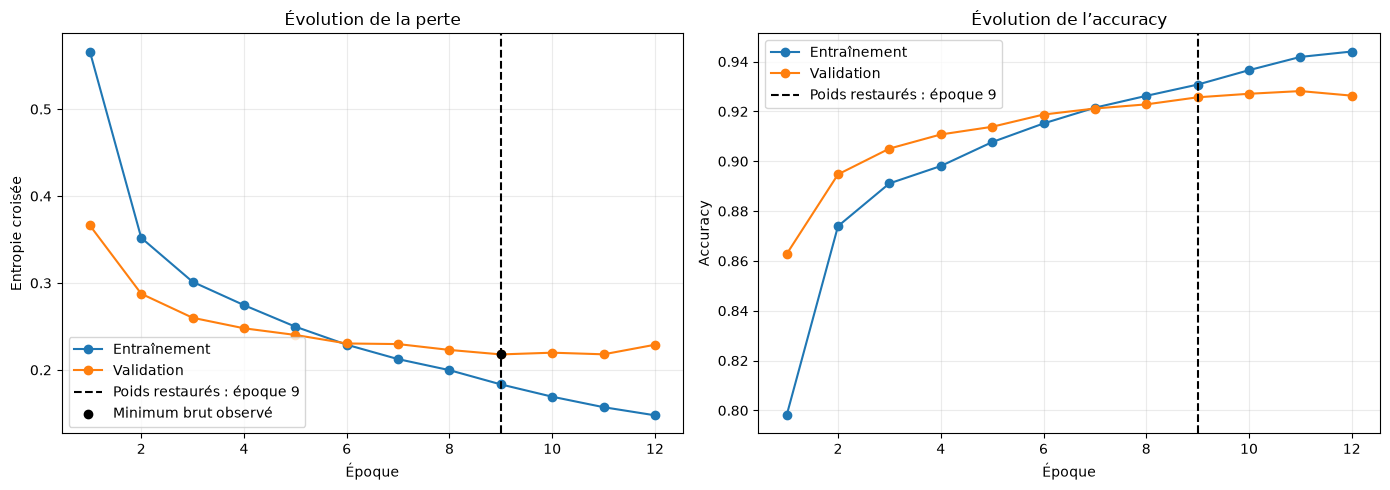

In [18]:
pertes_train = np.asarray(historique_cnn.history["loss"])
pertes_validation = np.asarray(historique_cnn.history["val_loss"])
accuracies_train = np.asarray(historique_cnn.history["accuracy"])
accuracies_validation = np.asarray(
    historique_cnn.history["val_accuracy"]
)

nombre_epoques = len(pertes_train)
epoques = np.arange(1, nombre_epoques + 1)
indice_minimum_val = int(np.argmin(pertes_validation))
epoque_minimum_val = indice_minimum_val + 1
epoque_retenue_callback = int(arret_anticipe.best_epoch) + 1
arret_declenche = arret_anticipe.stopped_epoch > 0
mises_a_jour_adam = int(modele_cnn.optimizer.iterations.numpy())

cles_attendues = {"loss", "accuracy", "val_loss", "val_accuracy"}
assert cles_attendues <= historique_cnn.history.keys()
assert 1 <= nombre_epoques <= EPOQUES_MAX
assert all(
    len(serie) == nombre_epoques
    for serie in [
        pertes_validation, accuracies_train, accuracies_validation
    ]
)
assert np.all(np.isfinite(pertes_train))
assert np.all(np.isfinite(pertes_validation))
assert np.all(pertes_train >= 0) and np.all(pertes_validation >= 0)
assert np.all((accuracies_train >= 0) & (accuracies_train <= 1))
assert np.all((accuracies_validation >= 0) & (accuracies_validation <= 1))
assert mises_a_jour_adam == nombre_epoques * LOTS_PAR_EPOQUE
assert 0 <= arret_anticipe.best_epoch < nombre_epoques
np.testing.assert_allclose(
    arret_anticipe.best, pertes_validation[arret_anticipe.best_epoch]
)
for poids_courant, meilleur_poids in zip(
    modele_cnn.get_weights(), arret_anticipe.best_weights
):
    np.testing.assert_array_equal(poids_courant, meilleur_poids)

print("Époques exécutées             :", nombre_epoques)
print("Arrêt anticipé déclenché      :", arret_declenche)
print("Minimum brut de val_loss     : époque", epoque_minimum_val)
print("Époque retenue par le callback :", epoque_retenue_callback)
print("Loss train au minimum        :", f"{pertes_train[indice_minimum_val]:.4f}")
print("Val loss minimale            :", f"{pertes_validation[indice_minimum_val]:.4f}")
print("Accuracy train correspondante :", f"{accuracies_train[indice_minimum_val]:.2%}")
print("Accuracy val correspondante   :", f"{accuracies_validation[indice_minimum_val]:.2%}")
print("Mises à jour Adam            :", mises_a_jour_adam)

print("\nDétail par époque")
print(f"{'Époque':>6} {'loss':>9} {'val_loss':>10} {'acc.':>9} {'val_acc.':>10}")
for indice in range(nombre_epoques):
    print(
        f"{indice + 1:>6} "
        f"{pertes_train[indice]:>9.4f} "
        f"{pertes_validation[indice]:>10.4f} "
        f"{accuracies_train[indice]:>8.2%} "
        f"{accuracies_validation[indice]:>9.2%}"
    )

figure, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epoques, pertes_train, marker="o", label="Entraînement")
axes[0].plot(epoques, pertes_validation, marker="o", label="Validation")
axes[0].axvline(
    epoque_retenue_callback, color="black", linestyle="--",
    label=f"Poids restaurés : époque {epoque_retenue_callback}",
)
axes[0].scatter(
    epoque_minimum_val, pertes_validation[indice_minimum_val],
    color="black", zorder=3, label="Minimum brut observé",
)
axes[0].set_title("Évolution de la perte")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Entropie croisée")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(epoques, accuracies_train, marker="o", label="Entraînement")
axes[1].plot(epoques, accuracies_validation, marker="o", label="Validation")
axes[1].axvline(
    epoque_retenue_callback, color="black", linestyle="--",
    label=f"Poids restaurés : époque {epoque_retenue_callback}",
)
axes[1].set_title("Évolution de l’accuracy")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Accuracy")
axes[1].grid(alpha=0.25)
axes[1].legend()

figure.tight_layout()
plt.show()

### 8.5 Interprétation des résultats obtenus

L’entraînement a exécuté **12 époques** sur les 20 autorisées, soit 4 500 mises à jour Adam. L’arrêt anticipé s’est déclenché après trois époques consécutives sans amélioration suffisante de `val_loss`.

Des époques 1 à 9, la perte d’entraînement passe de 0.5662 à 0.1833 et la perte de validation de 0.3662 à 0.2178. Les deux diminuent nettement : le CNN apprend des caractéristiques utiles qui se généralisent à la validation. Au début, `val_loss` est inférieure à `loss`. Cela reste cohérent, car le Dropout est actif pendant l’entraînement mais désactivé pendant la validation, et la perte d’entraînement agrège des mini-lots pendant que les poids évoluent.

Le minimum de validation est atteint à l’**époque 9** :

- `loss = 0.1833` ;
- `val_loss = 0.2178` ;
- `accuracy = 93.08 %` ;
- `val_accuracy = 92.57 %`.

Après l’époque 9, la perte d’entraînement continue à diminuer jusqu’à 0.1478, tandis que la perte de validation fluctue puis remonte jusqu’à 0.2290 à l’époque 12. L’écart entre les deux pertes s’agrandit : c’est un **début de surapprentissage**. Il ne s’agit pas d’un échec complet, car la validation reste globalement stable, mais poursuivre l’entraînement ferait surtout progresser l’ajustement au train.

L’accuracy de validation atteint même son maximum observé de 92.82 % à l’époque 11, alors que sa perte est moins bonne qu’à l’époque 9. Ce n’est pas contradictoire : l’accuracy regarde seulement la classe gagnante, tandis que l’entropie croisée pénalise aussi une confiance excessive dans les erreurs. Comme nous surveillons `val_loss`, le callback restaure correctement les poids de l’**époque 9**, et non ceux de l’époque 11 ou 12.

Cette analyse repose uniquement sur l’entraînement et la validation. L’arrêt anticipé limite le surapprentissage sans garantir à lui seul la généralisation. Le score final n’est donc pas encore connu : le jeu de test n’a toujours pas été évalué.

**Étape suivante :** effectuer une unique évaluation sur le test, puis construire la matrice de confusion et calculer précision, rappel et F1-score par classe.